# End-to-End Cardiovascular Disease Risk Prediction

## Project Overview
This project builds and deploys an interpretable, production-ready machine learning pipeline to predict cardiovascular disease risk from clinical metrics.

### Key Objectives & Findings:
- **Clinical Problem:** Binary classification (`0` = Healthy, `1` = Cardiovascular Disease).
- **Core Challenge:** False Negatives (missing a diseased patient) carry far higher clinical risk than False Positives.
- **Top Predictors:** Systolic Blood Pressure, Mean Arterial Pressure (MAP), and Age drive over 60% of model decisions.
- **Winning Model:** Tuned **XGBoost Classifier** achieving **0.8038 ROC-AUC** and **73.59% accuracy**.
- **Threshold Optimization:** Tuning the decision cutoff to **0.40** raises screening Recall from 68.25% to 77.91%, catching roughly 650 additional at-risk patients with minimal precision loss.

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

### Load the table

In [0]:
df = spark.table("cardio_sil").toPandas()

print(f"Raw records: {len(df):,}")
display(df.head())

Raw records: 68,669


id,gender,height,weight,systolic_bp,diastolic_bp,cholesterol,gluc,smoke,alco,active,cardio,age_years,BMI,BP_Category
24,2,172,112.0,120,80,1,1,0,0,0,1,46.0,37.85830178474852,Hypertension
30,2,163,83.0,120,80,1,1,0,0,1,0,54.0,31.239414355075468,Hypertension
31,1,157,69.0,130,80,1,1,0,0,1,0,59.0,27.993022029291247,Hypertension
44,1,159,60.0,110,70,1,1,0,0,1,0,40.0,23.73323840037973,Normal
45,1,160,73.0,130,85,1,1,0,0,0,1,57.0,28.515624999999993,Hypertension


### Clean and prepare the data

In [0]:
clean_mask = (
    (df["systolic_bp"] > df["diastolic_bp"]) &
    (df["systolic_bp"].between(70, 240)) &
    (df["diastolic_bp"].between(40, 150)) &
    (df["BMI"].between(14, 60))
)

df_clean = df.loc[clean_mask].copy()

print(
    f"Clean records: {len(df_clean):,} "
    f"(removed {len(df) - len(df_clean):,})"
)

# Derived blood-pressure features
df_clean["pulse_pressure"] = (
    df_clean["systolic_bp"] - df_clean["diastolic_bp"]
)
df_clean["map"] = (
    df_clean["diastolic_bp"] + df_clean["pulse_pressure"] / 3
)

print("Missing values:", int(df_clean.isna().sum().sum()))
print("Duplicate rows:", int(df_clean.duplicated().sum()))

Clean records: 68,593 (removed 76)
Missing values: 0
Duplicate rows: 0


### Explore the target and BP Category

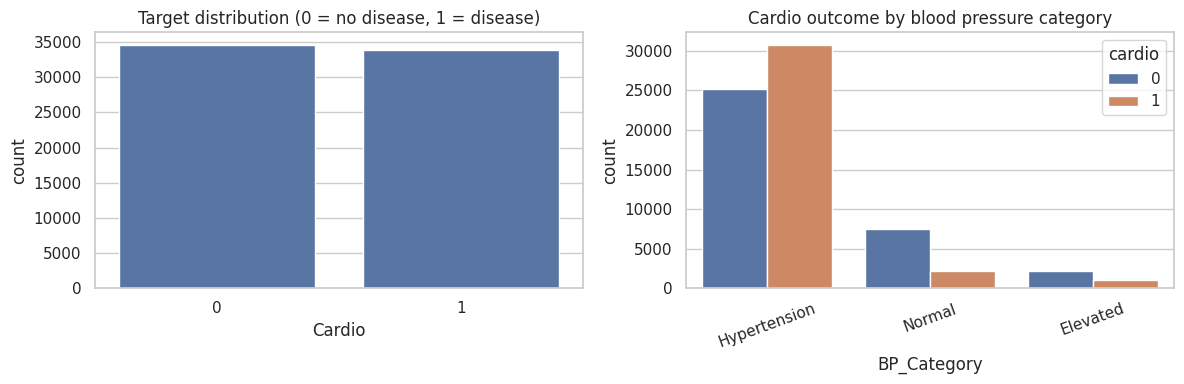

cardio
0    0.505314
1    0.494686
Name: proportion, dtype: float64

In [0]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df_clean, x="cardio", ax=axes[0])
axes[0].set_title("Target distribution (0 = no disease, 1 = disease)")
axes[0].set_xlabel("Cardio")

sns.countplot(data=df_clean, x="BP_Category", hue="cardio", ax=axes[1])
axes[1].set_title("Cardio outcome by blood pressure category")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

display(df_clean["cardio"].value_counts(normalize=True).rename("proportion"))

### Correlation heatmap

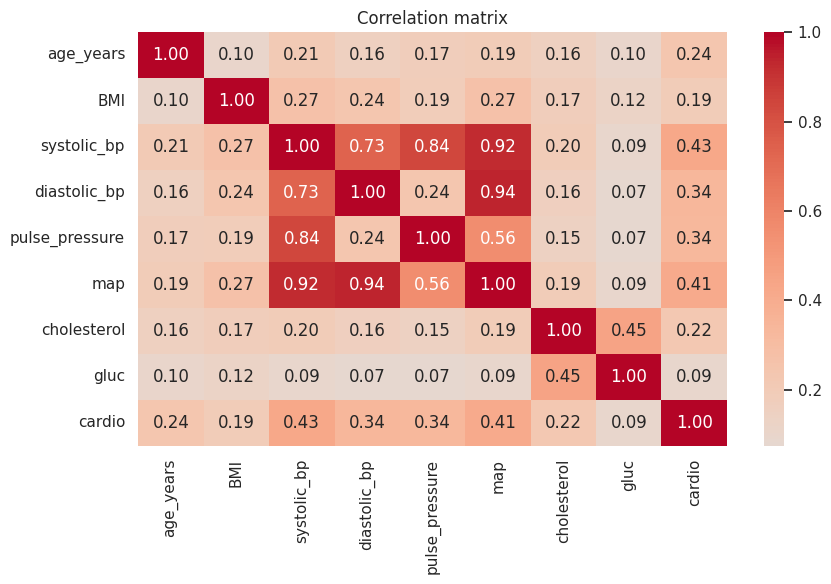

In [0]:
corr_cols = [
    "age_years", "BMI", "systolic_bp", "diastolic_bp",
    "pulse_pressure", "map", "cholesterol", "gluc", "cardio"
]

plt.figure(figsize=(9, 6))
sns.heatmap(
    df_clean[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

### Define features and split the data

In [0]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone

num_features = [
    "age_years", "BMI", "systolic_bp", "diastolic_bp",
    "pulse_pressure", "map", "height", "weight"
]
cat_features = ["BP_Category"]
binary_features = [
    "cholesterol", "gluc", "gender", "smoke", "alco", "active"
]
features = num_features + cat_features + binary_features

X = df_clean[features].copy()
y = df_clean["cardio"].copy()

# Set aside the test set. Do not use it to choose a model or threshold.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Use part of the training data for model comparison and threshold selection.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print(f"Fit rows: {len(X_fit):,}")
print(f"Validation rows: {len(X_val):,}")
print(f"Test rows: {len(X_test):,}")

Fit rows: 43,899
Validation rows: 10,975
Test rows: 13,719


### Preprocessing

In [0]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [0]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), cat_features)
    ],
    remainder="passthrough"
)

#### Compare models on the validation set
- The test set is not used in this comparison.

In [0]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        eval_metric="logloss"
    )
}

comparison_results = []
fitted_models = {}

for name, classifier in models.items():
    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    pipe.fit(X_fit, y_fit)

    val_predictions = pipe.predict(X_val)
    val_probabilities = pipe.predict_proba(X_val)[:, 1]

    comparison_results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_val, val_probabilities),
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1": f1_score(y_val, val_predictions, zero_division=0)
    })

    fitted_models[name] = pipe

comparison_df = (
    pd.DataFrame(comparison_results)
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(4))

Model,ROC-AUC,Accuracy,Precision,Recall,F1
XGBoost,0.7982,0.7362,0.7544,0.692,0.7219
Random Forest,0.7961,0.7355,0.7663,0.6694,0.7146
Logistic Regression,0.7901,0.7271,0.7525,0.6681,0.7078


#### Choose a threshold using validation data

In [0]:
# Use the XGBoost model for threshold selection.
validation_model = fitted_models["XGBoost"]
val_probabilities = validation_model.predict_proba(X_val)[:, 1]

thresholds = [0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
threshold_results = []

for threshold in thresholds:
    val_predictions = (val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

chosen_threshold = float(
    threshold_df.loc[threshold_df["F1"].idxmax(), "Threshold"]
)
print(f"Chosen validation threshold: {chosen_threshold:.2f}")

Threshold,Precision,Recall,F1
0.35,0.6611,0.8269,0.7348
0.4,0.6957,0.7815,0.7361
0.45,0.7238,0.7364,0.73
0.5,0.7544,0.692,0.7219
0.55,0.779,0.6473,0.707
0.6,0.8015,0.6018,0.6874


Chosen validation threshold: 0.40


#### Refit on training data and evaluate once on the test set

Decision threshold: 0.40
Test ROC-AUC:  0.8038
Test accuracy: 0.7296
Test precision: 0.7053
Test recall: 0.7791
Test F1: 0.7404

Classification report:
                precision    recall  f1-score   support

No disease (0)       0.76      0.68      0.72      6932
   Disease (1)       0.71      0.78      0.74      6787

      accuracy                           0.73     13719
     macro avg       0.73      0.73      0.73     13719
  weighted avg       0.73      0.73      0.73     13719



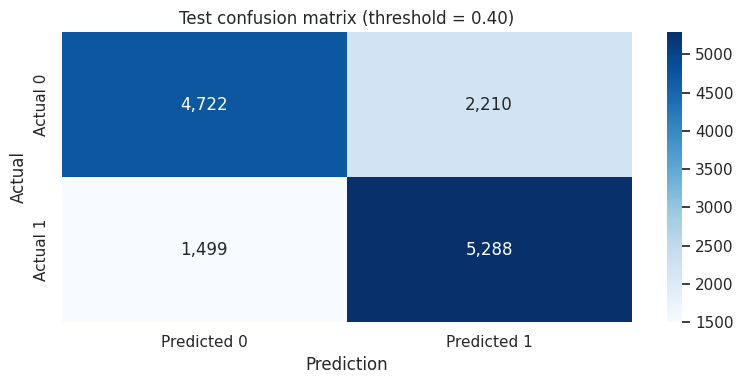

In [0]:
champion_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        eval_metric="logloss"
    ))
])

# Refit using all training data after selecting the threshold.
champion_pipeline.fit(X_train, y_train)

test_probabilities = champion_pipeline.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= chosen_threshold).astype(int)

print(f"Decision threshold: {chosen_threshold:.2f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, test_probabilities):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, test_predictions):.4f}")
print(
    f"Test precision: "
    f"{precision_score(y_test, test_predictions, zero_division=0):.4f}"
)
print(
    f"Test recall: "
    f"{recall_score(y_test, test_predictions, zero_division=0):.4f}"
)
print(
    f"Test F1: "
    f"{f1_score(y_test, test_predictions, zero_division=0):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["No disease (0)", "Disease (1)"],
    zero_division=0
))

cm = confusion_matrix(y_test, test_predictions)
sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title(f"Test confusion matrix (threshold = {chosen_threshold:.2f})")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

#### Log the final model to MLflow

In [0]:
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

input_example = X_train.head(5)
output_example = champion_pipeline.predict(input_example)
signature = infer_signature(input_example, output_example)

with mlflow.start_run(run_name="xgb_cardiovascular_champion"):
    mlflow.log_params({
        "model_type": "XGBClassifier",
        "n_estimators": 200,
        "max_depth": 4,
        "learning_rate": 0.05,
        "decision_threshold": chosen_threshold
    })

    mlflow.log_metrics({
        "accuracy": accuracy_score(y_test, test_predictions),
        "precision": precision_score(
            y_test, test_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, test_predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, test_predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, test_probabilities)
    })

    mlflow.sklearn.log_model(
        sk_model=champion_pipeline,
        name="champion_pipeline",
        signature=signature,
        input_example=input_example
    )

print("Model and test metrics logged to MLflow.")

/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
🔗 View Logged Model at: https://dbc-2ddcdd1f-40c1.cloud.databricks.com/ml/experiments/1584179285322252/models/m-145f5ec83fd0484eab7bdcb4293eaa13?o=7474650607225437


Model and test metrics logged to MLflow.


Feature,Importance
systolic_bp,0.61539626
cholesterol,0.08075455
age_years,0.07829216
map,0.073196046
active,0.025774822
BP_Category_Normal,0.018835433
smoke,0.018735822
gluc,0.015803806
weight,0.014905658
BMI,0.013870147


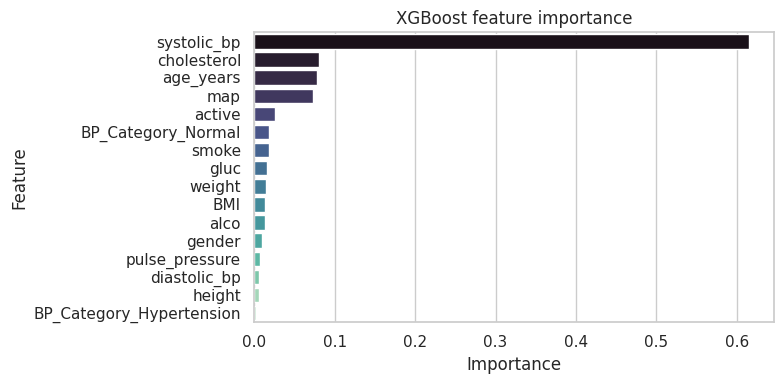

In [0]:
fitted_preprocessor = champion_pipeline.named_steps["preprocessor"]

encoded_category_names = (
    fitted_preprocessor
    .named_transformers_["cat"]
    .get_feature_names_out(cat_features)
    .tolist()
)

transformed_feature_names = (
    num_features + encoded_category_names + binary_features
)

importances = (
    champion_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance_df = (
    pd.DataFrame({
        "Feature": transformed_feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
)

display(feature_importance_df)

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="mako",
    legend=False
)
plt.title("XGBoost feature importance")
plt.tight_layout()
plt.show()

### Example prediction

In [0]:
sample_patient = pd.DataFrame([{
    "age_years": 54.0,
    "BMI": 28.5,
    "systolic_bp": 140,
    "diastolic_bp": 90,
    "pulse_pressure": 50,
    "map": 90 + 50 / 3,
    "height": 165,
    "weight": 78.0,
    "BP_Category": "Hypertension",
    "cholesterol": 2,
    "gluc": 1,
    "gender": 1,
    "smoke": 0,
    "alco": 0,
    "active": 1
}])

risk_probability = champion_pipeline.predict_proba(sample_patient)[0, 1]
predicted_class = int(risk_probability >= chosen_threshold)

print(f"Model score: {risk_probability:.2%}")
print(f"Predicted class at threshold {chosen_threshold:.2f}: {predicted_class}")

Model score: 83.58%
Predicted class at threshold 0.40: 1
